# FoodSeg103 Inference Notebook
Welcome! This notebook allows you to instantly generate segmentation masks on your own food images using your previously trained DeepLabV3+ model.\n\n
**Before you start, make sure you have attached these 3 Datasets to this Kaggle session:**
1. The original **FoodSeg103 Dataset** (needed to load the food class names).
2. Your folder holding the model checkpoints (e.g., `results` from before).
3. Your folder holding your custom images you want to test.

In [2]:
!pip install -q pretrainedmodels efficientnet_pytorch==0.7.1 timm==0.9.2
!pip install -q segmentation-models-pytorch --no-deps

In [3]:
import os
import glob
import numpy as np
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
import cv2

# =============== Hardcoded Configs ===============
NUM_CLASSES = 104
IGNORE_INDEX = 255
IMG_SIZE = 416
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


In [4]:
class_names = []

# Dynamically find the FoodSeg103 dataset path
paths = glob.glob('/kaggle/input/**/ImageSets', recursive=True)
foodseg_paths = [p for p in paths if 'foodseg' in p.lower()]

if not foodseg_paths and not paths:
    raise FileNotFoundError("FoodSeg103 dataset not found! Please Add Data to the notebook.")

ROOT_DIR = os.path.dirname(foodseg_paths[0] if foodseg_paths else paths[0])
label_file = os.path.join(ROOT_DIR, "category_id.txt")

with open(label_file, "r") as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            class_names.append(parts[1])

print(f"\u2705 Loaded {len(class_names)} food class labels!")

✅ Loaded 104 food class labels!


In [5]:
# =============== Load Model =====================
# 1. Build the empty architecture
model = smp.DeepLabV3Plus(
    encoder_name="mobilenet_v2",
    encoder_weights=None,      # No pretrained download, we are supplying the weights!
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None
).to(DEVICE)

# 2. Find and Load your trained weights!
# Search dynamically for the best_deeplabv3plus... file in Kaggle inputs
weight_paths = glob.glob('/kaggle/input/**/best_deeplabv3plus_mobilenetv2.pth', recursive=True)

if not weight_paths:
    raise FileNotFoundError("Weights not found! Did you add your 'results' folder to this notebook Data?")

print(f"Loading weights from: {weight_paths[0]}")
checkpoint = torch.load(weight_paths[0], map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model"])

model.eval() # Lock the model into prediction mode
print("\u2705 Model successfully loaded and ready for inference!")

Loading weights from: /kaggle/input/datasets/dheerajmalavath/foodseg-results/results/best_deeplabv3plus_mobilenetv2.pth
✅ Model successfully loaded and ready for inference!


In [6]:
# =============== Inference Function ===============
def predict_custom_image(image_path, write_labels=True):
    # 1. Load image
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image {image_path} not found!")
        
    img = Image.open(image_path).convert("RGB")
    
    # 2. Transform shape and colors
    to_tensor = transforms.ToTensor()
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    
    img_resized = transforms.functional.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)
    img_tensor = normalize(to_tensor(img_resized))
    images = img_tensor.unsqueeze(0).to(DEVICE)
    
    # 3. Predict!
    with torch.amp.autocast('cuda', enabled=(DEVICE.type == 'cuda')):
        logits = model(images)
    preds = logits.argmax(1).cpu().numpy()
    
    # 4. Process the visual outputs
    mask_pred = preds[0]
    img_disp = np.clip(img_tensor.permute(1,2,0).cpu().numpy() * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406], 0, 1)
    
    unique_classes = np.unique(mask_pred)
    cmap = plt.get_cmap("nipy_spectral", NUM_CLASSES)
    img_plt = (img_disp * 255).astype(np.uint8).copy()
    
    if write_labels:
        for c in unique_classes:
            if c == IGNORE_INDEX:
                continue    
            bin_mask = (mask_pred == c).astype(np.uint8)
            contours, _ = cv2.findContours(bin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for cnt in contours:
                if cv2.contourArea(cnt) < 200:
                    continue
                M = cv2.moments(cnt)
                if M["m00"] > 0:
                    cx = int(M["m10"]/M["m00"])
                    cy = int(M["m01"]/M["m00"])
                    cv2.putText(img_plt, class_names[c], (cx, cy),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
    
    # 5. Plot
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    ax[0].imshow(img_disp)
    ax[0].set_title("Your Custom Image")
    ax[0].axis("off")
    ax[1].imshow(mask_pred, cmap=cmap, vmin=0, vmax=NUM_CLASSES-1)
    ax[1].set_title("AI Prediction")
    ax[1].axis("off")
    ax[2].imshow(img_plt)
    ax[2].set_title("Overlay with labels")
    ax[2].axis("off")
    plt.show()
print("\u2705 Prediction function loaded!")

✅ Prediction function loaded!


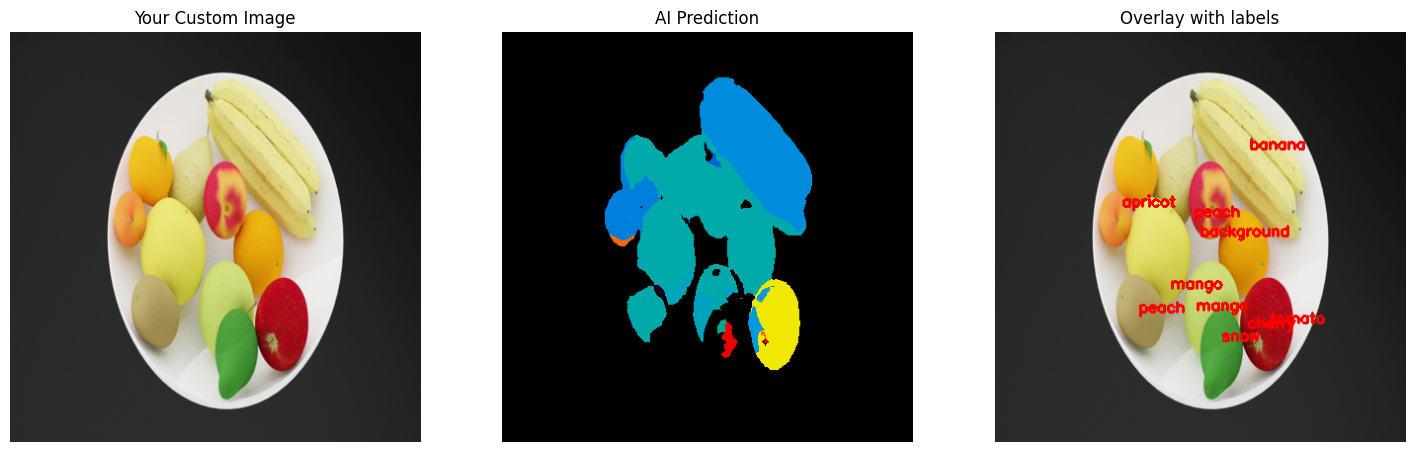

In [7]:
# Paste your custom image path here!
# You can copy this path from the 'Input' sidebar on Kaggle.
CUSTOM_IMAGE_PATH = "/kaggle/input/datasets/dheerajmalavath/my-test-picture/pic1.jpg"

predict_custom_image(CUSTOM_IMAGE_PATH)